# ML from Scratch - 11 - DBSCAN

## Importing

In [1]:
import importlib
import my_dbscan

importlib.reload(my_dbscan)
from my_dbscan import DBSCAN

## Synthetic Data

In [2]:
from sklearn.datasets import make_moons
import numpy as np

np.random.seed(42)

X, labels = make_moons(1000, noise=0.05, random_state=42)

X[:5], labels[:5]

(array([[-0.02137124,  0.40618608],
        [ 0.97670045, -0.45832306],
        [ 0.90405882, -0.37651952],
        [ 0.37736316, -0.39703717],
        [-0.84192557,  0.53058695]]),
 array([1, 1, 1, 1, 0]))

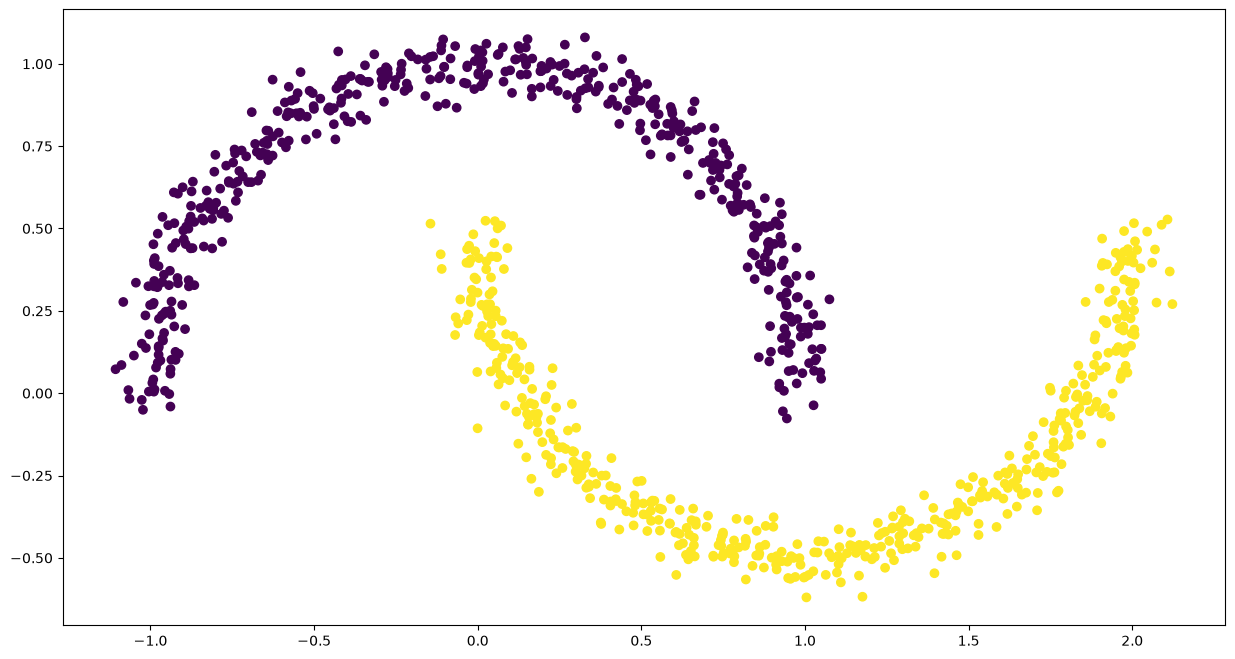

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,8))

plt.scatter(X[:, 0], X[:, 1], c=labels)

plt.show()

In [4]:
model = DBSCAN(epsilon=0.2, min_samples=5)
model.fit(X)

In [5]:
from sklearn.metrics import adjusted_rand_score

labels_pred = model.fit_predict(X)

adjusted_rand_score(labels, labels_pred)

1.0

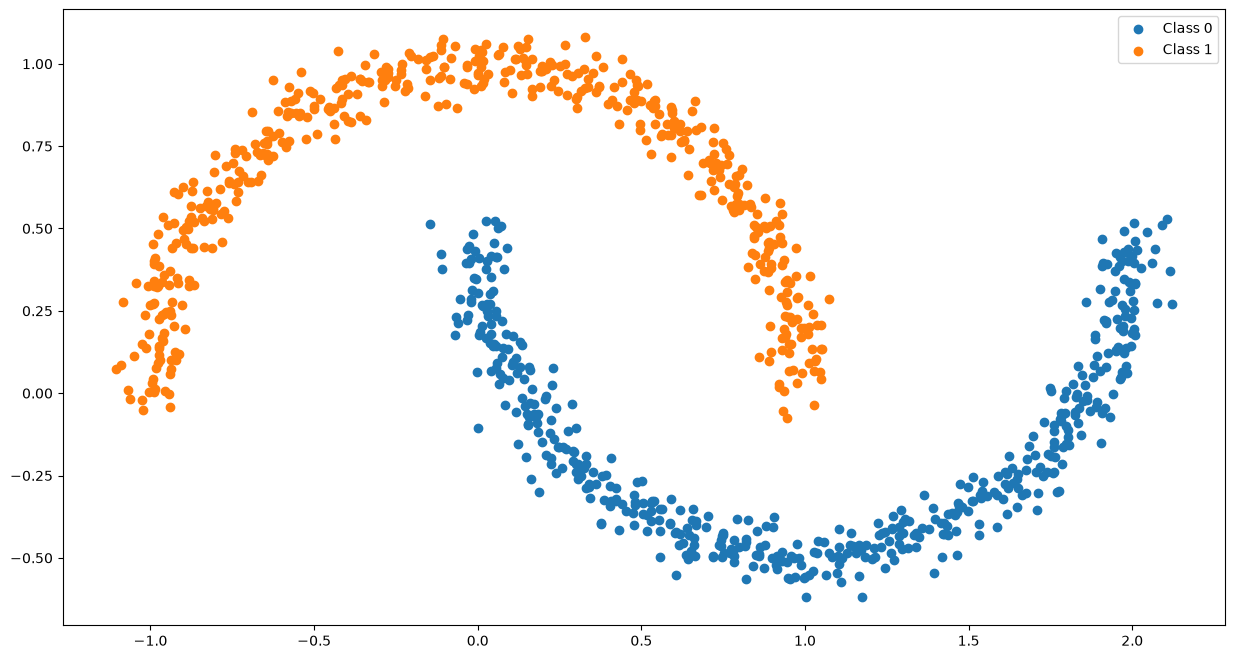

In [6]:
plt.figure(figsize=(15,8))

classes = np.unique(labels_pred)

for label in classes:
    plt.scatter(X[labels_pred == label, 0], X[labels_pred == label, 1], label=f"Class {label}")

plt.legend()
plt.show()

## Customer Segementation

In [7]:
import pandas as pd

df_preprocessed = pd.read_csv('../data/customer_segmentation/preprocessed/full.csv').set_index('record_id')

df_preprocessed.head()

,num__age_years,num__income_value,num__tenure_months,num__monthly_spend,num__purchase_rate,num__order_value,num__promo_usage_rate,num__return_rate,num__browse_minutes,num__support_contacts,str__payment_channel_Channel_A,str__payment_channel_Channel_B,str__payment_channel_Channel_C,str__market_area_Area_A,str__market_area_Area_B,str__market_area_Area_C
record_id,,,,,,,,,,,,,,,,
R47904,-0.972267,-0.724224,-0.012994,1.272619,-0.446287,0.832825,-0.380540,0.079485,2.037126,-0.427282,1.0,0.0,0.0,0.0,0.0,1.0
R20485,-1.102530,-0.740590,-0.813880,-0.687202,-0.686621,0.254534,0.026607,-0.445933,-0.457380,1.152902,0.0,1.0,0.0,1.0,0.0,0.0
R48306,-1.363056,0.960157,0.467538,-0.237846,-0.634004,0.117695,-0.787688,-0.883782,0.297572,-1.217373,1.0,0.0,0.0,1.0,0.0,0.0
R06809,-0.972267,-0.752655,-0.813880,-0.676771,-0.693732,0.205308,-0.227860,1.918450,-1.216121,0.362810,0.0,0.0,1.0,0.0,1.0,0.0
R01502,1.242203,0.695783,1.460638,0.841489,0.859194,-0.952968,0.281074,0.079485,-0.143114,0.362810,0.0,0.0,1.0,0.0,1.0,0.0


### Model Training

#### My Model

In [8]:
model = DBSCAN(epsilon=0.5)

labels = model.fit_predict(df_preprocessed)

#### Sci-Kit Learn Model

In [9]:
from sklearn.cluster import DBSCAN as DBSCAN_sklearn

model_sklearn = DBSCAN_sklearn(eps=0.5)

labels_sklearn = model_sklearn.fit_predict(df_preprocessed)

### Submission

In [10]:
submission_sklearn = pd.DataFrame(labels_sklearn, index=df_preprocessed.index, columns=['cluster'])

submission_sklearn.to_csv('../data/customer_segmentation/submissions/submission_dbscan_my_model.csv')

In [11]:
submission_sklearn = pd.DataFrame(labels_sklearn, index=df_preprocessed.index, columns=['cluster'])

submission_sklearn.to_csv('../data/customer_segmentation/submissions/submission_dbscan_sklearn.csv')

Kaggle Score for my model: `0.00096` (adjusted rand index)

Kaggle Score for SciKit-Learn model: `0.00096` (adjusted rand index)